In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)
gun_sayisi = 60
sicaklik = np.random.randint(10, 38, size=gun_sayisi)
hafta_sonu = np.random.choice(['Evet', 'Hayır'], size=gun_sayisi, p=[2/7, 5/7])
musteri_sayisi = np.random.randint(50, 200, size=gun_sayisi)
kampanya = np.random.choice(['Var', 'Yok'], size=gun_sayisi, p=[0.3, 0.7])
hafta_sonu_etkisi = np.where(hafta_sonu == 'Evet', 1500, 0)
kampanya_etkisi = np.where(kampanya == 'Var', 2000, 0)
ciro = (musteri_sayisi * 90) + (sicaklik * 40) + hafta_sonu_etkisi + kampanya_etkisi + np.random.normal(0, 400, size=gun_sayisi)

df_kafe = pd.DataFrame({
    'Sıcaklık': sicaklik,
    'Hafta sonu': hafta_sonu,
    'Müşteri sayısı': musteri_sayisi,
    'Kampanya': kampanya,
    'Ciro': ciro
})

print(df_kafe.head())

   Sıcaklık Hafta sonu  Müşteri sayısı Kampanya          Ciro
0        16      Hayır              76      Var   9549.933205
1        29       Evet             186      Yok  18913.258043
2        24       Evet              64      Var  10639.738957
3        20       Evet             139      Var  17340.042265
4        17      Hayır              91      Yok   9163.800426


In [2]:
df_kafe.loc[5, 'Sıcaklık'] = np.nan
df_kafe.loc[15, 'Sıcaklık'] = np.nan
df_kafe.loc[22, 'Müşteri sayısı'] = np.nan
df_kafe.loc[40, 'Müşteri sayısı'] = np.nan
df_kafe.loc[50, 'Sıcaklık'] = np.nan
print("--- EKSİK (NULL) DEĞER SAYILARI ---")
print(df_kafe.isnull().sum())

--- EKSİK (NULL) DEĞER SAYILARI ---
Sıcaklık          3
Hafta sonu        0
Müşteri sayısı    2
Kampanya          0
Ciro              0
dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

X = df_kafe[['Sıcaklık', 'Hafta sonu', 'Müşteri sayısı', 'Kampanya']]
y = df_kafe['Ciro']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
sicaklik_ortalama = X_train['Sıcaklık'].mean()
musteri_ortalama = X_train['Müşteri sayısı'].mean()
X_train['Sıcaklık'] = X_train['Sıcaklık'].fillna(sicaklik_ortalama)
X_train['Müşteri sayısı'] = X_train['Müşteri sayısı'].fillna(musteri_ortalama)
X_test['Sıcaklık'] = X_test['Sıcaklık'].fillna(sicaklik_ortalama)
X_test['Müşteri sayısı'] = X_test['Müşteri sayısı'].fillna(musteri_ortalama)

print("--- EĞİTİM SETİ EKSİK DEĞER SAYILARI ---")
print(X_train.isnull().sum())
print("\n--- TEST SETİ EKSİK DEĞER SAYILARI ---")
print(X_test.isnull().sum())

--- EĞİTİM SETİ EKSİK DEĞER SAYILARI ---
Sıcaklık          0
Hafta sonu        0
Müşteri sayısı    0
Kampanya          0
dtype: int64

--- TEST SETİ EKSİK DEĞER SAYILARI ---
Sıcaklık          0
Hafta sonu        0
Müşteri sayısı    0
Kampanya          0
dtype: int64


In [5]:
ortalama_ciro = df_kafe['Ciro'].mean()
maksimum_ciro = df_kafe['Ciro'].max()
toplam_musteri = df_kafe['Müşteri sayısı'].sum()
print(f"Günlük Ortalama Ciro: {ortalama_ciro:.2f} TL")
print(f"Maksimum Ciro: {maksimum_ciro:.2f} TL")
print(f"60 Günlük Toplam Müşteri Sayısı: {toplam_musteri} kişi")

Günlük Ortalama Ciro: 13633.92 TL
Maksimum Ciro: 20578.23 TL
60 Günlük Toplam Müşteri Sayısı: 7443.0 kişi


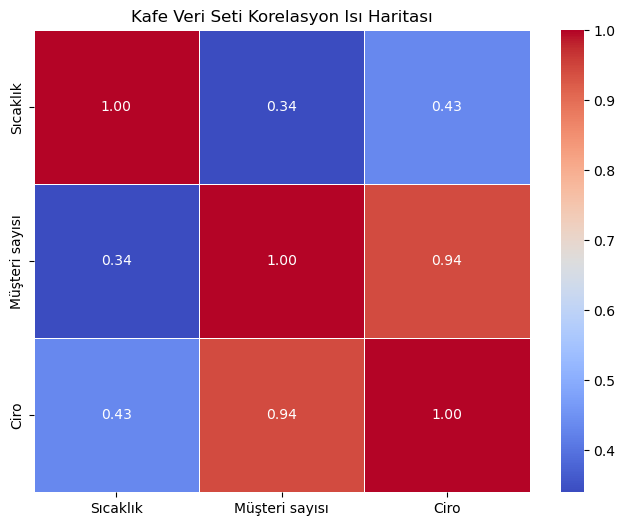

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

korelasyon_matrisi = df_kafe[['Sıcaklık', 'Müşteri sayısı', 'Ciro']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(korelasyon_matrisi, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Kafe Veri Seti Korelasyon Isı Haritası', fontsize=12)
plt.show()

In [7]:
X_train['Hafta sonu'] = X_train['Hafta sonu'].map({'Evet': 1, 'Hayır': 0})
X_train['Kampanya'] = X_train['Kampanya'].map({'Var': 1, 'Yok': 0})
X_test['Hafta sonu'] = X_test['Hafta sonu'].map({'Evet': 1, 'Hayır': 0})
X_test['Kampanya'] = X_test['Kampanya'].map({'Var': 1, 'Yok': 0})
print("--- ENCODING SONRASI EĞİTİM VERİSİ ---")
print(X_train.head())

--- ENCODING SONRASI EĞİTİM VERİSİ ---
    Sıcaklık  Hafta sonu  Müşteri sayısı  Kampanya
31      21.0           0           178.0         0
3       20.0           1           139.0         1
52      18.0           1           150.0         1
17      12.0           0            77.0         0
8       28.0           0           101.0         0


In [8]:
import numpy as np
X_train['Sıcak Gün'] = np.where(X_train['Sıcaklık'] >= 25, 1, 0)
X_test['Sıcak Gün'] = np.where(X_test['Sıcaklık'] >= 25, 1, 0)
print("--- ÖZELLİK MÜHENDİSLİĞİ SONRASI EĞİTİM VERİSİ ---")
print(X_train.head())

--- ÖZELLİK MÜHENDİSLİĞİ SONRASI EĞİTİM VERİSİ ---
    Sıcaklık  Hafta sonu  Müşteri sayısı  Kampanya  Sıcak Gün
31      21.0           0           178.0         0          0
3       20.0           1           139.0         1          0
52      18.0           1           150.0         1          0
17      12.0           0            77.0         0          0
8       28.0           0           101.0         0          1


In [9]:
giris_sutunlari = ['Sıcaklık', 'Hafta sonu', 'Müşteri sayısı', 'Kampanya', 'Sıcak Gün']
X_train_final = X_train[giris_sutunlari]
X_test_final = X_test[giris_sutunlari]
print("--- MODEL GİRDİLERİ (X_train_final) ---")
print(X_train_final.head())

--- MODEL GİRDİLERİ (X_train_final) ---
    Sıcaklık  Hafta sonu  Müşteri sayısı  Kampanya  Sıcak Gün
31      21.0           0           178.0         0          0
3       20.0           1           139.0         1          0
52      18.0           1           150.0         1          0
17      12.0           0            77.0         0          0
8       28.0           0           101.0         0          1


In [10]:
print("--- EĞİTİM HEDEF DEĞİŞKENİ (y_train) İLK 5 DEĞERİ ---")
print(y_train.head())
print("\n--- TEST HEDEF DEĞİŞKENİ (y_test) İLK 5 DEĞERİ ---")
print(y_test.head())

--- EĞİTİM HEDEF DEĞİŞKENİ (y_train) İLK 5 DEĞERİ ---
31    17170.819918
3     17340.042265
52    17729.572726
17     7314.162197
8     10517.990944
Name: Ciro, dtype: float64

--- TEST HEDEF DEĞİŞKENİ (y_test) İLK 5 DEĞERİ ---
0      9549.933205
5     16388.201095
36     5724.043696
45    11576.479418
13     8908.344741
Name: Ciro, dtype: float64


In [11]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train_final, y_train)

print("Model başarıyla eğitildi!")
print("Öğrenilen Katsayılar (Weights):", model.coef_)
print("Öğrenilen Sabit Terim (Intercept):", model.intercept_)

Model başarıyla eğitildi!
Öğrenilen Katsayılar (Weights): [  -2.96243759 1772.71445357   87.61633678 1532.26274275 1045.00686445]
Öğrenilen Sabit Terim (Intercept): 906.1697545903298


In [12]:
import pandas as pd
y_pred_ciro = model.predict(X_test_final)
kafe_karsilastirma = pd.DataFrame({
    'Gerçek Ciro (TL)': y_test.values,
    'Tahmin Edilen Ciro (TL)': y_pred_ciro
})

print("--- KAFE CİROSU: GERÇEK vs TAHMİN ---")
print(kafe_karsilastirma)

--- KAFE CİROSU: GERÇEK vs TAHMİN ---
    Gerçek Ciro (TL)  Tahmin Edilen Ciro (TL)
0        9549.933205              9049.875091
1       16388.201095             15989.987201
2        5724.043696              5405.932953
3       11576.479418             11590.679312
4        8908.344741              9309.692118
5       13354.942531             13261.314586
6        9243.143315             10305.709291
7        8842.048784              8574.933265
8        9492.943564             10460.204901
9       19985.281044             19057.153455
10      10066.396761             10699.703756
11      16961.779648             16603.301558


In [13]:
import pandas as pd

yeni_sicaklik = 28
yeni_hafta_sonu = 1  
yeni_musteri = 160
yeni_kampanya = 1    
yeni_sicak_gun = 1    

yeni_senaryo = pd.DataFrame({
    'Sıcaklık': [yeni_sicaklik],
    'Hafta sonu': [yeni_hafta_sonu],
    'Müşteri sayısı': [yeni_musteri],
    'Kampanya': [yeni_kampanya],
    'Sıcak Gün': [yeni_sicak_gun]
})

tahmini_ciro = model.predict(yeni_senaryo)
print("--- YENİ SENARYO CİRO TAHMİNİ ---")
print(f"Hava Sıcaklığı: {yeni_sicaklik}°C | Müşteri Sayısı: {yeni_musteri}")
print(f"Hafta Sonu: {'Evet' if yeni_hafta_sonu==1 else 'Hayır'} | Kampanya: {'Var' if yeni_kampanya==1 else 'Yok'}")
print(f"Öngörülen Tahmini Ciro: {tahmini_ciro[0]:.2f} TL")

--- YENİ SENARYO CİRO TAHMİNİ ---
Hava Sıcaklığı: 28°C | Müşteri Sayısı: 160
Hafta Sonu: Evet | Kampanya: Var
Öngörülen Tahmini Ciro: 19191.82 TL


In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X_train_tek = X_train[['Müşteri sayısı']]
X_test_tek = X_test[['Müşteri sayısı']]
model_tek = LinearRegression()
model_tek.fit(X_train_tek, y_train)
y_pred_tek = model_tek.predict(X_test_tek)
y_pred_coklu = model.predict(X_test_final)

print("--- MODEL 1 (Sadece Müşteri Sayısı) ---")
print(f"R² Skoru (Başarı Oranı): {r2_score(y_test, y_pred_tek):.4f}")
print(f"Hata Kareler Ortalaması (MSE): {mean_squared_error(y_test, y_pred_tek):.2f}")

print("\n--- MODEL 2 (Tüm Değişkenler / Çoklu) ---")
print(f"R² Skoru (Başarı Oranı): {r2_score(y_test, y_pred_coklu):.4f}")
print(f"Hata Kareler Ortalaması (MSE): {mean_squared_error(y_test, y_pred_coklu):.2f}")

--- MODEL 1 (Sadece Müşteri Sayısı) ---
R² Skoru (Başarı Oranı): 0.9312
Hata Kareler Ortalaması (MSE): 1095218.95

--- MODEL 2 (Tüm Değişkenler / Çoklu) ---
R² Skoru (Başarı Oranı): 0.9780
Hata Kareler Ortalaması (MSE): 350572.60
